# 🌍 Động đất Toàn cầu — Phân tích Xu hướng & Dự đoán Số trận (1990–2013)

**Sinh viên:** Trần Khánh Duy &nbsp;|&nbsp; **MSSV:** 24636801 &nbsp;|&nbsp; **Môn học:** Phân tích Dữ liệu và Trí tuệ Nhân tạo

**Nguồn dữ liệu:** USGS — United States Geological Survey (Earthquake Catalog API), các trận có độ lớn M ≥ 5.5

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

ACCENT = "#FF8C00"
plt.style.use("dark_background")
plt.rcParams.update({
    "figure.facecolor": "#0d1117",
    "axes.facecolor": "#0d1117",
    "axes.edgecolor": "#30363d",
    "axes.labelcolor": "#e6edf3",
    "text.color": "#e6edf3",
    "xtick.color": "#8b949e",
    "ytick.color": "#8b949e",
    "grid.color": "#21262d",
    "font.size": 11,
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
})
PALETTE = sns.dark_palette(ACCENT, n_colors=12, reverse=True)
sns.set_palette(PALETTE)

## 1. Thu thập & Khảo sát Dữ liệu

In [2]:
DATA_URL = ("https://earthquake.usgs.gov/fdsnws/event/1/query?format=csv"
            "&starttime=1990-01-01&endtime=2013-12-31&minmagnitude=5.5&orderby=time-asc")

df = pd.read_csv(DATA_URL)
df.shape

(12202, 22)

In [3]:
df.dtypes

time                object
latitude           float64
longitude          float64
depth              float64
mag                float64
magType             object
nst                float64
gap                float64
dmin               float64
rms                float64
net                 object
id                  object
updated             object
place               object
type                object
horizontalError    float64
depthError         float64
magError           float64
magNst             float64
status              object
locationSource      object
magSource           object
dtype: object

In [4]:
df[["time", "latitude", "longitude", "depth", "mag", "magType", "place", "type"]].head()

,time,latitude,longitude,depth,mag,magType,place,type
0,1990-01-02T01:25:06.560Z,8.344,127.441,40.9,5.6,mw,Philippine Islands region,earthquake
1,1990-01-02T20:21:32.620Z,13.408,144.439,135.8,5.8,mw,"23 km W of Agat Village, Guam",earthquake
2,1990-01-04T05:32:21.040Z,-15.397,-172.850,53.5,6.5,mw,"118 km ENE of Hihifo, Tonga",earthquake
3,1990-01-05T10:10:21.810Z,-8.800,106.442,29.0,5.8,mw,"200 km S of Pelabuhanratu, Indonesia",earthquake
4,1990-01-05T13:03:44.300Z,-19.258,-69.529,108.7,5.5,mw,"118 km SE of Arica, Chile",earthquake


In [5]:
df[["time", "latitude", "longitude", "depth", "mag", "magType", "place", "type"]].isnull().sum()

time         0
latitude     0
longitude    0
depth        0
mag          0
magType      0
place        0
type         0
dtype: int64

## 2. Tiền xử lý & Làm sạch Dữ liệu

In [6]:
df = df[["time", "latitude", "longitude", "depth", "mag", "magType", "place", "type"]].copy()

df["datetime"] = pd.to_datetime(df["time"], utc=True, errors="coerce").dt.tz_localize(None)
df["mag"] = pd.to_numeric(df["mag"], errors="coerce")
df["depth"] = pd.to_numeric(df["depth"], errors="coerce")

# Chỉ giữ động đất tự nhiên (loại bỏ nổ mìn, thử hạt nhân...)
df = df[df["type"] == "earthquake"]
df = df.dropna(subset=["datetime", "mag", "depth", "latitude", "longitude"])
df = df.drop_duplicates()

df["year"] = df["datetime"].dt.year
df["month"] = df["datetime"].dt.month
df["month_name"] = df["datetime"].dt.month_name()

# Khu vực = phần sau dấu phẩy cuối cùng của cột place (hoặc cả chuỗi nếu không có dấu phẩy)
df["region"] = df["place"].fillna("Unknown").str.split(",").str[-1].str.strip()

# Phân nhóm độ sâu
df["depth_class"] = pd.cut(df["depth"], bins=[-np.inf, 70, 300, np.inf],
                           labels=["Nông (<70 km)", "Trung bình (70-300 km)", "Sâu (>300 km)"])

df = df[(df["year"] >= 1990) & (df["year"] <= 2013)]
df.shape

(12185, 14)

## 3. Thống kê Mô tả

In [7]:
df[["year", "mag", "depth"]].describe()

,year,mag,depth
count,12185.000000,12185.000000,12185.000000
mean,2001.745999,5.876273,70.584084
std,6.950928,0.423972,127.093723
min,1990.000000,5.500000,-3.000000
25%,1996.000000,5.600000,10.000000
50%,2002.000000,5.700000,33.000000
75%,2008.000000,6.000000,49.000000
max,2013.000000,9.100000,691.600000


In [8]:
df["depth_class"].value_counts()

depth_class
Nông (<70 km)             9847
Trung bình (70-300 km)    1586
Sâu (>300 km)              752
Name: count, dtype: int64

In [9]:
df["magType"].value_counts()

magType
mwc    5512
mw     2466
mwb    2287
mww     933
mb      789
ms      159
ml       17
mwr      13
md        8
mh        1
Name: count, dtype: int64

In [10]:
df["region"].value_counts().head(10)

region
Indonesia           1478
Japan                848
Papua New Guinea     815
Tonga                582
Russia               500
Philippines          489
Vanuatu              472
Chile                410
Alaska               398
Solomon Islands      369
Name: count, dtype: int64

## 4. Phân tích Khám phá Dữ liệu (EDA)

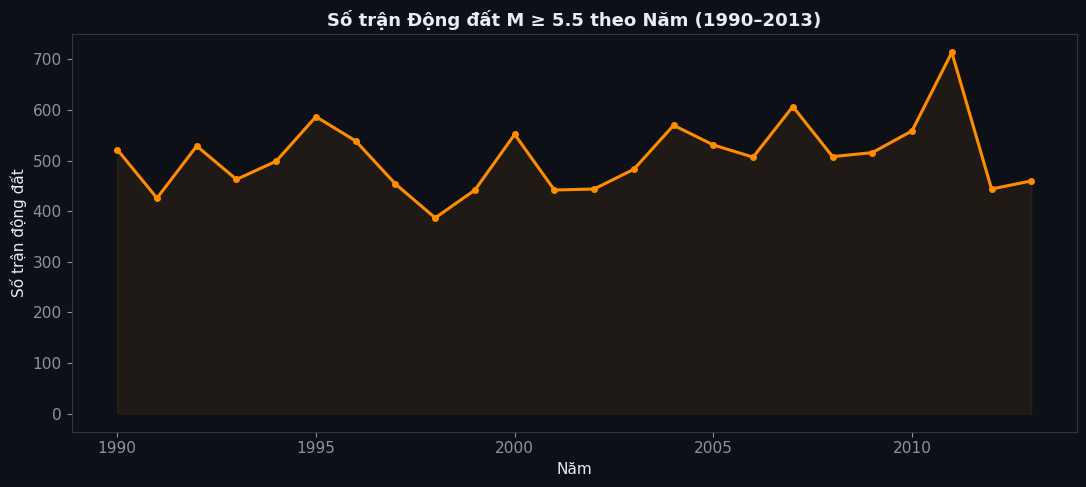

In [11]:
yearly = df.groupby("year").size()

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(yearly.index, yearly.values, color=ACCENT, linewidth=2.2, marker="o", markersize=4)
ax.fill_between(yearly.index, yearly.values, color=ACCENT, alpha=0.08)
ax.set_title("Số trận Động đất M ≥ 5.5 theo Năm (1990–2013)")
ax.set_xlabel("Năm")
ax.set_ylabel("Số trận động đất")
plt.tight_layout()
plt.show()

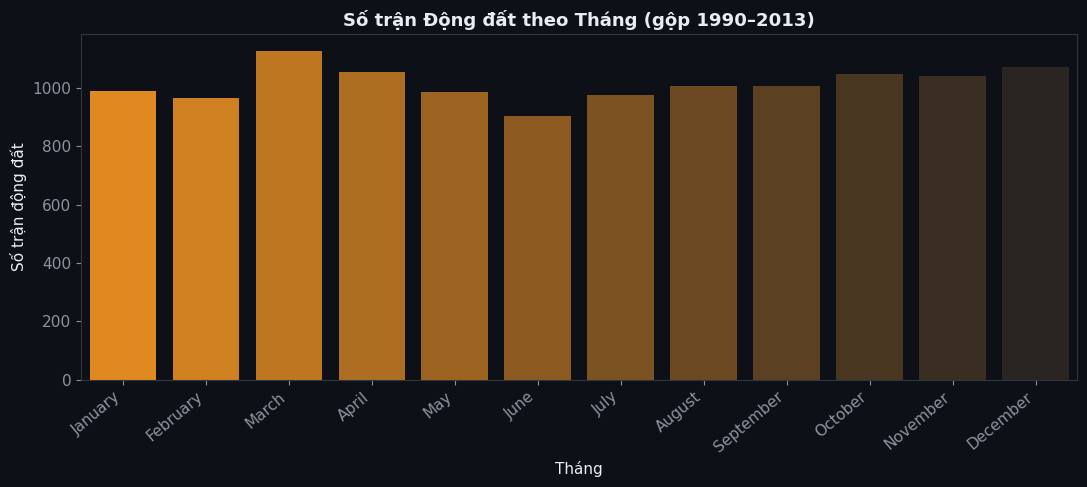

In [12]:
month_order = ["January","February","March","April","May","June",
               "July","August","September","October","November","December"]
monthly = df.groupby("month_name").size().reindex(month_order)

fig, ax = plt.subplots(figsize=(11, 5))
sns.barplot(x=monthly.index, y=monthly.values, hue=monthly.index,
            palette=PALETTE, legend=False, ax=ax)
ax.set_title("Số trận Động đất theo Tháng (gộp 1990–2013)")
ax.set_xlabel("Tháng")
ax.set_ylabel("Số trận động đất")
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.show()

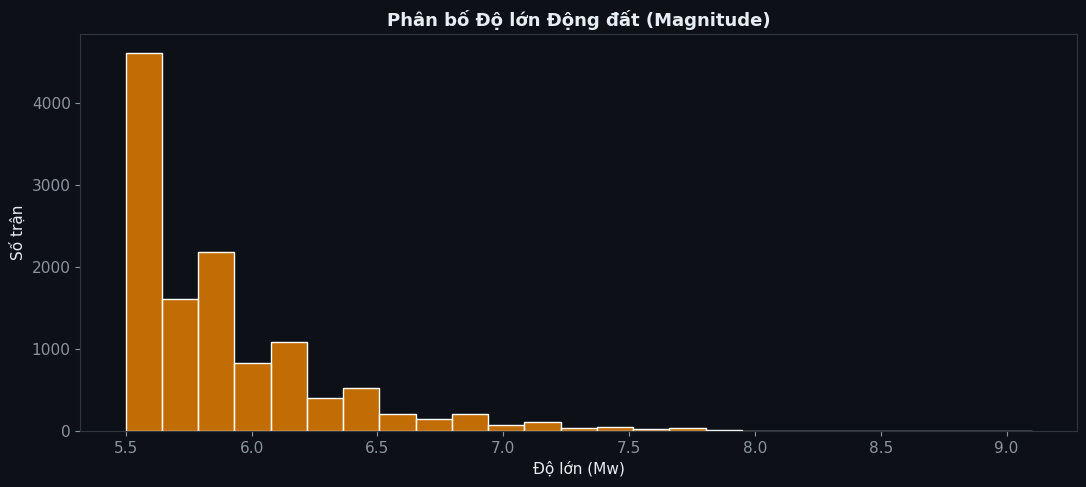

In [13]:
fig, ax = plt.subplots(figsize=(11, 5))
sns.histplot(df["mag"], bins=25, color=ACCENT, ax=ax)
ax.set_title("Phân bố Độ lớn Động đất (Magnitude)")
ax.set_xlabel("Độ lớn (Mw)")
ax.set_ylabel("Số trận")
plt.tight_layout()
plt.show()

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_9152\1038237414.py:4: UserWarning: The palette list has more values (12) than needed (10), which may not be intended.
  sns.barplot(x=top_regions.values, y=top_regions.index, hue=top_regions.index,


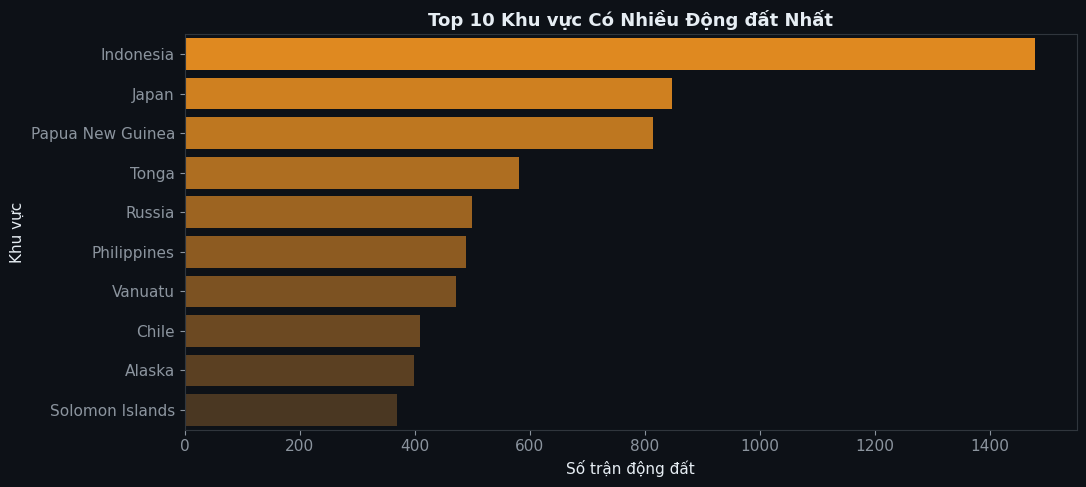

In [14]:
top_regions = df["region"].value_counts().head(10)

fig, ax = plt.subplots(figsize=(11, 5))
sns.barplot(x=top_regions.values, y=top_regions.index, hue=top_regions.index,
            palette=PALETTE, legend=False, ax=ax)
ax.set_title("Top 10 Khu vực Có Nhiều Động đất Nhất")
ax.set_xlabel("Số trận động đất")
ax.set_ylabel("Khu vực")
plt.tight_layout()
plt.show()

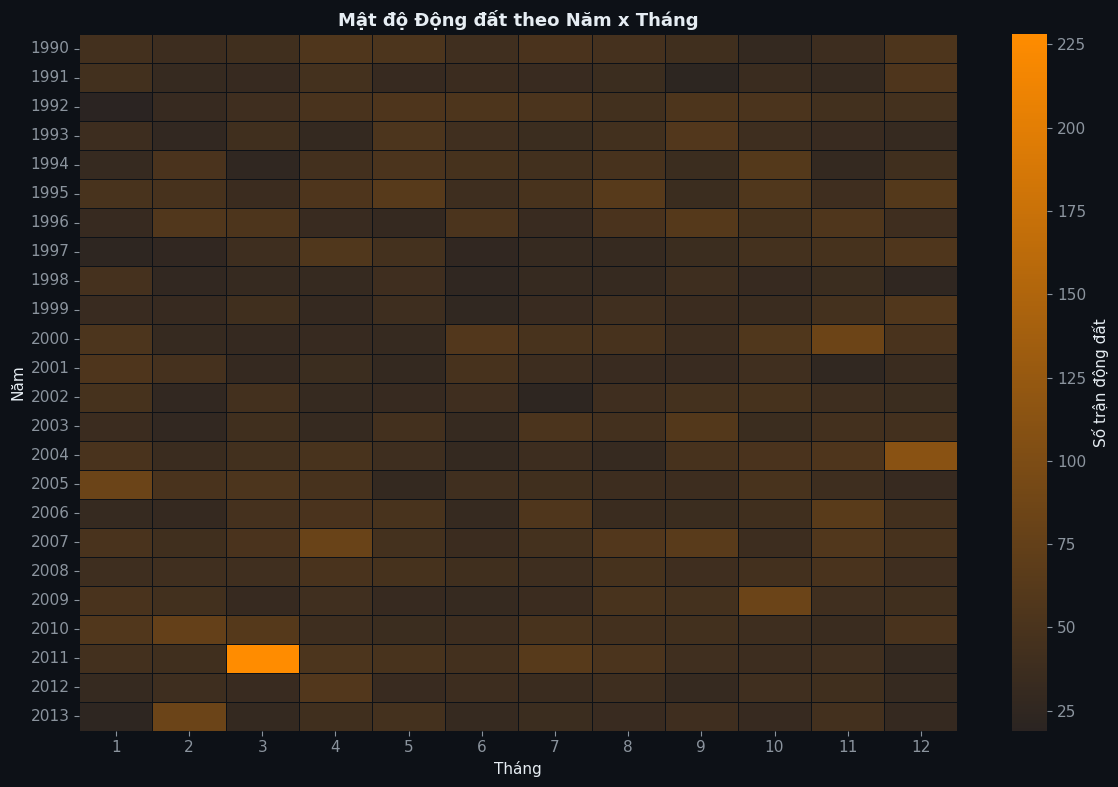

In [15]:
pivot = df.pivot_table(index="year", columns="month", values="datetime", aggfunc="count")

fig, ax = plt.subplots(figsize=(12, 8))
sns.heatmap(pivot, cmap=sns.dark_palette(ACCENT, as_cmap=True), linewidths=0.4,
            linecolor="#0d1117", ax=ax, cbar_kws={"label": "Số trận động đất"})
ax.set_title("Mật độ Động đất theo Năm x Tháng")
ax.set_xlabel("Tháng")
ax.set_ylabel("Năm")
plt.tight_layout()
plt.show()

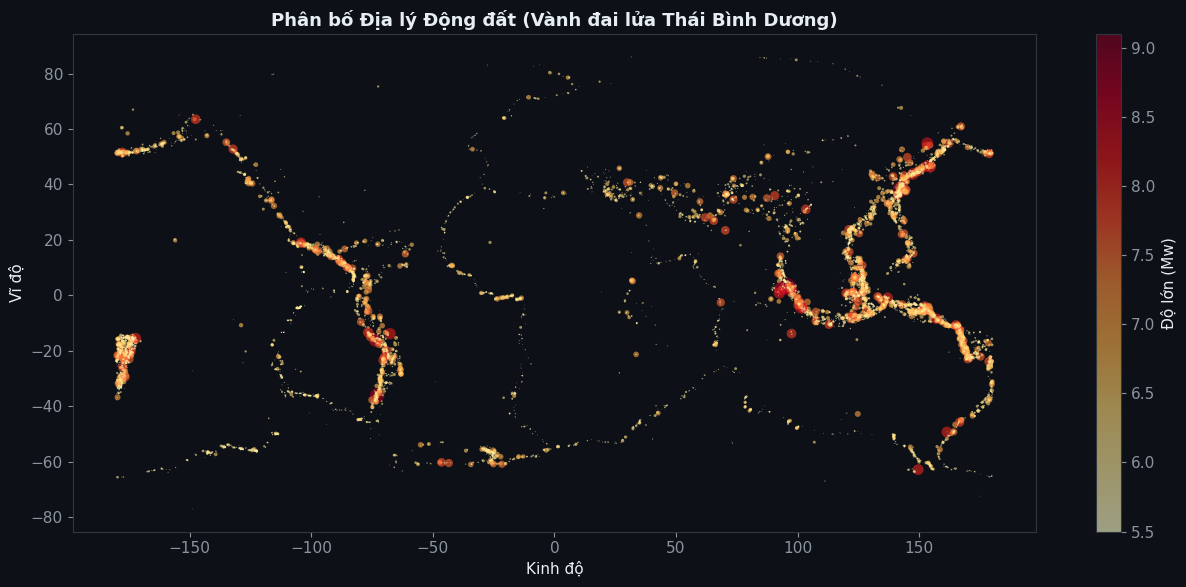

In [16]:
fig, ax = plt.subplots(figsize=(13, 6))
sc = ax.scatter(df["longitude"], df["latitude"], c=df["mag"], cmap="YlOrRd",
                s=(df["mag"] - 5) ** 3 * 2, alpha=0.6, linewidths=0)
plt.colorbar(sc, ax=ax, label="Độ lớn (Mw)")
ax.set_title("Phân bố Địa lý Động đất (Vành đai lửa Thái Bình Dương)")
ax.set_xlabel("Kinh độ")
ax.set_ylabel("Vĩ độ")
plt.tight_layout()
plt.show()

## 5. Mô hình Dự đoán Xu hướng

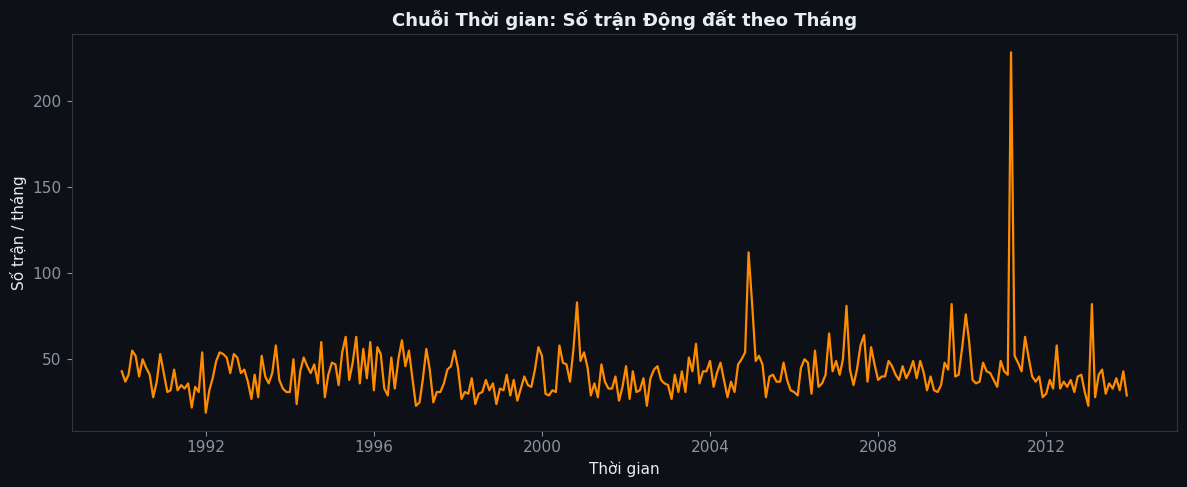

In [17]:
ts = df.set_index("datetime").resample("MS").size()

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(ts.index, ts.values, color=ACCENT, linewidth=1.6)
ax.set_title("Chuỗi Thời gian: Số trận Động đất theo Tháng")
ax.set_xlabel("Thời gian")
ax.set_ylabel("Số trận / tháng")
plt.tight_layout()
plt.show()

In [18]:
X = np.arange(len(ts)).reshape(-1, 1)
y = ts.values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2, mse

(-0.0037676448414332153, 738.0616364055239)

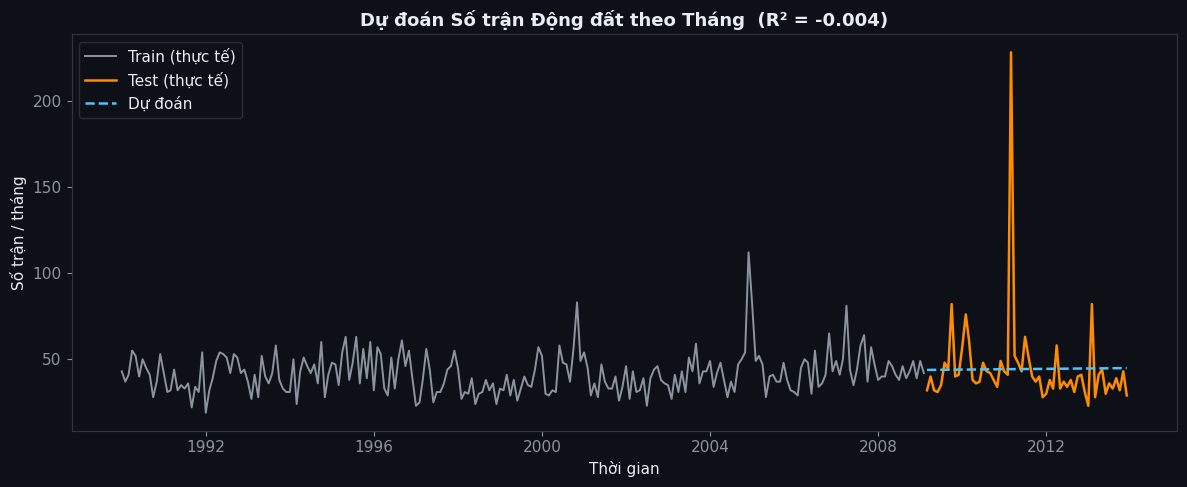

In [19]:
fig, ax = plt.subplots(figsize=(12, 5))
idx_train = ts.index[:len(y_train)]
idx_test = ts.index[len(y_train):]

ax.plot(idx_train, y_train, color="#8b949e", linewidth=1.4, label="Train (thực tế)")
ax.plot(idx_test, y_test, color=ACCENT, linewidth=1.8, label="Test (thực tế)")
ax.plot(idx_test, y_pred, color="#4dc3ff", linewidth=1.8, linestyle="--", label="Dự đoán")
ax.set_title(f"Dự đoán Số trận Động đất theo Tháng  (R² = {r2:.3f})")
ax.set_xlabel("Thời gian")
ax.set_ylabel("Số trận / tháng")
ax.legend(facecolor="#0d1117", edgecolor="#30363d")
plt.tight_layout()
plt.show()

## 6. Tổng kết

In [20]:
summary = {
    "Tổng số bản ghi sau làm sạch": len(df),
    "Khoảng thời gian": f"{df['year'].min()}-{df['year'].max()}",
    "Độ lớn trung bình": round(df["mag"].mean(), 2),
    "Độ lớn lớn nhất": df["mag"].max(),
    "Nhóm độ sâu phổ biến nhất": df["depth_class"].value_counts().idxmax(),
    "Tháng nhiều động đất nhất": monthly.idxmax(),
    "Khu vực đứng đầu": top_regions.idxmax(),
    "R² mô hình dự đoán": round(r2, 3),
    "MSE mô hình dự đoán": round(mse, 1),
}
pd.Series(summary).to_frame("Giá trị")

,Giá trị
Tổng số bản ghi sau làm sạch,12185
Khoảng thời gian,1990-2013
Độ lớn trung bình,5.88
Độ lớn lớn nhất,9.1
Nhóm độ sâu phổ biến nhất,Nông (<70 km)
Tháng nhiều động đất nhất,March
Khu vực đứng đầu,Indonesia
R² mô hình dự đoán,-0.004
MSE mô hình dự đoán,738.1


### Nhận xét

- Số trận động đất M ≥ 5.5 mỗi năm dao động quanh một mức tương đối ổn định, không có xu hướng tăng/giảm rõ rệt; đây là hiện tượng tự nhiên chứ không phải do hoạt động báo cáo như dữ liệu UFO.
- Động đất tập trung chủ yếu dọc **Vành đai lửa Thái Bình Dương** (Nhật Bản, Indonesia, Chile, Tonga, Papua New Guinea...).
- Mô hình hồi quy tuyến tính chỉ nắm được xu hướng tuyến tính nên R² thấp là điều dễ hiểu; có thể cải thiện bằng mô hình chuỗi thời gian (ARIMA, Poisson regression).